# Telecom Customer Churn Prediction

Goal: predict whether a telecom customer will leave, using account and service data
(~7,000 customers, 20 features). Main challenge: the target is imbalanced, so I compare
class weighting, under/over-sampling and SMOTE using recall and F1 instead of accuracy.

# 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

## 2. Load data and make dataframe

In [2]:
df = pd.read_csv("IT_customer_churn.csv")
df.sample(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6155,Male,0,Yes,No,5,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.35,126.05,Yes
5911,Male,0,Yes,No,7,No,No phone service,DSL,Yes,Yes,No,No,No,No,Month-to-month,No,Mailed check,34.20,256.6,No
6774,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
1547,Female,0,Yes,No,63,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Electronic check,107.50,6873.75,Yes
6377,Male,0,No,No,1,No,No phone service,DSL,No,Yes,No,Yes,No,Yes,Month-to-month,Yes,Mailed check,44.65,44.65,Yes


In [3]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [4]:
df.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [5]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

# 3. Do Some EDA

In [6]:
df.isnull().sum().sum()

np.int64(0)

In [7]:
pd.to_numeric(df.TotalCharges,errors='coerce').isnull().sum() 

np.int64(11)

In [8]:
df1 = df[df["TotalCharges"]!=" "]

In [9]:
df.shape

(7043, 20)

In [10]:
df1.shape

(7032, 20)

In [11]:
pd.to_numeric(df1.TotalCharges,errors='coerce').isnull().sum()

np.int64(0)

In [12]:
df1.TotalCharges = pd.to_numeric(df1.TotalCharges)

In [13]:
df1.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

# 4. Let's do some  Visualization

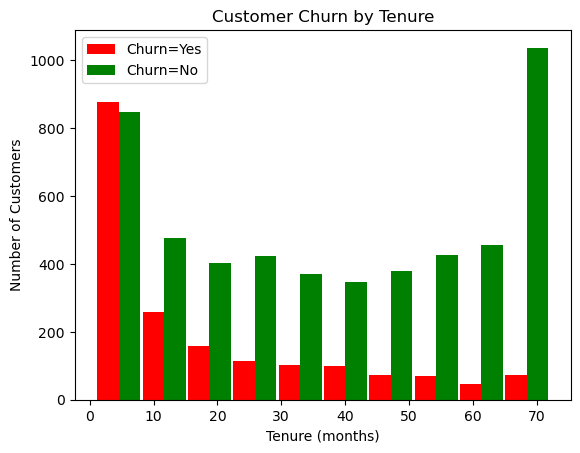

In [14]:
tenure_churn_no = df1[df1.Churn == 'No'].tenure
tenure_churn_yes = df1[df1.Churn == 'Yes'].tenure

plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.title("Customer Churn by Tenure")

plt.hist([tenure_churn_yes, tenure_churn_no], rwidth=0.95,
         color=['red', 'green'], label=['Churn=Yes', 'Churn=No'])
plt.legend()
plt.show()

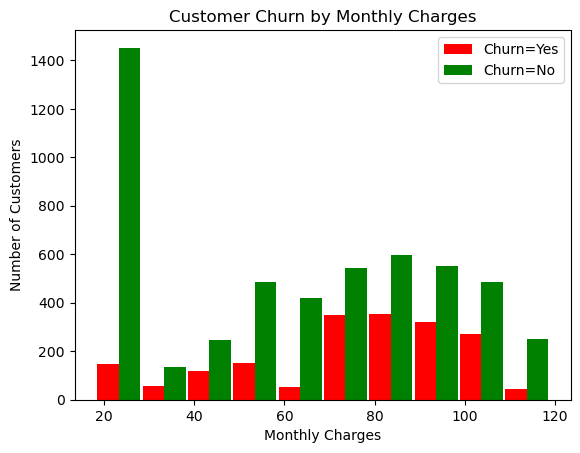

In [15]:
mc_churn_no = df1[df1.Churn == 'No'].MonthlyCharges
mc_churn_yes = df1[df1.Churn == 'Yes'].MonthlyCharges

plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.title("Customer Churn by Monthly Charges")

plt.hist([mc_churn_yes, mc_churn_no], rwidth=0.95,
         color=['red', 'green'], label=['Churn=Yes', 'Churn=No'])
plt.legend()
plt.show()

# 5. Data Preprocessing

In [16]:
def print_unique_col_values(df):
       for column in df:
            if df[column].dtypes=='object':
                print(f'{column}: {df[column].unique()}') 

In [17]:
print_unique_col_values(df1)

gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


In [18]:
df1.replace("No internet service","No",inplace=True)
df1.replace("No phone service","No",inplace=True)

In [19]:
df1

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,Female,0,Yes,Yes,11,No,No,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [20]:
yes_no_columns = ['Partner','Dependents','PhoneService','MultipleLines','OnlineSecurity','OnlineBackup',
                  'DeviceProtection','TechSupport','StreamingTV','StreamingMovies','PaperlessBilling','Churn']
for col in yes_no_columns:
    df1[col].replace({'Yes': 1,'No': 0},inplace=True)

In [21]:
for col in df1:
    print(f'{col}: {df1[col].unique()}') 

gender: ['Female' 'Male']
SeniorCitizen: [0 1]
Partner: [1 0]
Dependents: [0 1]
tenure: [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26 39]
PhoneService: [0 1]
MultipleLines: [0 1]
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: [0 1]
OnlineBackup: [1 0]
DeviceProtection: [0 1]
TechSupport: [0 1]
StreamingTV: [0 1]
StreamingMovies: [0 1]
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: [1 0]
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
MonthlyCharges: [29.85 56.95 53.85 ... 63.1  44.2  78.7 ]
TotalCharges: [  29.85 1889.5   108.15 ...  346.45  306.6  6844.5 ]
Churn: [0 1]


In [22]:
df1['gender'].replace({'Male': 1,'Female': 0},inplace=True)

In [23]:
for col in df1:
    print(f'{col}: {df1[col].unique()}') 

gender: [0 1]
SeniorCitizen: [0 1]
Partner: [1 0]
Dependents: [0 1]
tenure: [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26 39]
PhoneService: [0 1]
MultipleLines: [0 1]
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: [0 1]
OnlineBackup: [1 0]
DeviceProtection: [0 1]
TechSupport: [0 1]
StreamingTV: [0 1]
StreamingMovies: [0 1]
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: [1 0]
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
MonthlyCharges: [29.85 56.95 53.85 ... 63.1  44.2  78.7 ]
TotalCharges: [  29.85 1889.5   108.15 ...  346.45  306.6  6844.5 ]
Churn: [0 1]


In [24]:
df1 = pd.get_dummies(df1, columns=['Contract', 'PaymentMethod', 'InternetService'], dtype=int)
print(df1.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No']


### Train test split

In [25]:
from sklearn.model_selection import train_test_split

X = df1.drop('Churn', axis='columns')
y = df1['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=15, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(5625, 26) (1407, 26)
Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64
Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64


### Scaling

In [26]:
cols_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = MinMaxScaler()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print(X_train[cols_to_scale].describe().loc[['min', 'max']])
print(X_test[cols_to_scale].describe().loc[['min', 'max']])

     tenure  MonthlyCharges  TotalCharges
min     0.0             0.0           0.0
max     1.0             1.0           1.0
     tenure  MonthlyCharges  TotalCharges
min     0.0        0.002985     -0.000006
max     1.0        0.990547      1.001427


# 6. Train the model
**Use logistic regression classifier**

In [27]:
def log_reg(X_train, y_train, X_test, y_test, weights=None):
    if weights is None:
        model = LogisticRegression(max_iter=1000, random_state=15)
    else:
        model = LogisticRegression(class_weight={0: weights[0], 1: weights[1]},
                                   max_iter=1000, random_state=15)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print("Accuracy:", model.score(X_test, y_test), "\n")
    print(classification_report(y_test, y_pred))
    return model

In [28]:
print("--- بدون وزن ---")
model_base = log_reg(X_train, y_train, X_test, y_test)

--- بدون وزن ---
Accuracy: 0.8031272210376688 

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1033
           1       0.66      0.54      0.59       374

    accuracy                           0.80      1407
   macro avg       0.75      0.72      0.73      1407
weighted avg       0.79      0.80      0.80      1407



In [29]:
print("--- با وزن کلاس [1, 1.5] ---")
model_w = log_reg(X_train, y_train, X_test, y_test, weights=[1, 1.5])

--- با وزن کلاس [1, 1.5] ---
Accuracy: 0.7931769722814499 

              precision    recall  f1-score   support

           0       0.88      0.83      0.86      1033
           1       0.60      0.68      0.64       374

    accuracy                           0.79      1407
   macro avg       0.74      0.76      0.75      1407
weighted avg       0.80      0.79      0.80      1407



# 7. Imbalanced dataset

### Undersampling and Oversampling

In [30]:
train_df = X_train.copy()
train_df['Churn'] = y_train

df_class_0 = train_df[train_df['Churn'] == 0]
df_class_1 = train_df[train_df['Churn'] == 1]

n0, n1 = len(df_class_0), len(df_class_1)
print(n0, n1)

# --- Undersampling ---
train_under = pd.concat([df_class_0.sample(n1, random_state=15), df_class_1])
X_train_under = train_under.drop('Churn', axis='columns')
y_train_under = train_under['Churn']

# --- Oversampling ---
train_over = pd.concat([df_class_0, df_class_1.sample(n0, replace=True, random_state=15)])
X_train_over = train_over.drop('Churn', axis='columns')
y_train_over = train_over['Churn']

print("--- Undersampling ---")
model_under = log_reg(X_train_under, y_train_under, X_test, y_test)

print("--- Oversampling ---")
model_over = log_reg(X_train_over, y_train_over, X_test, y_test)

4130 1495
--- Undersampling ---
Accuracy: 0.7420042643923241 

              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1033
           1       0.51      0.78      0.62       374

    accuracy                           0.74      1407
   macro avg       0.71      0.75      0.71      1407
weighted avg       0.80      0.74      0.76      1407

--- Oversampling ---
Accuracy: 0.7398720682302772 

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1033
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1407
   macro avg       0.71      0.75      0.71      1407
weighted avg       0.80      0.74      0.75      1407



### SMOTE

In [31]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=15)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print(y_train_sm.value_counts())

print("--- SMOTE ---")
model_smote = log_reg(X_train_sm, y_train_sm, X_test, y_test)

Churn
0    4130
1    4130
Name: count, dtype: int64
--- SMOTE ---
Accuracy: 0.7611940298507462 

              precision    recall  f1-score   support

           0       0.89      0.77      0.83      1033
           1       0.54      0.73      0.62       374

    accuracy                           0.76      1407
   macro avg       0.71      0.75      0.72      1407
weighted avg       0.80      0.76      0.77      1407



# 8. Conclusion

Dataset is imbalanced (~73% stayed, ~27% churned), so accuracy alone is misleading.
I compared five approaches on a held-out test set that keeps the real class distribution.
To avoid data leakage, the split was done first, and the scaler and all resampling
(under/over-sampling, SMOTE) were fitted on the training set only.

| Method | Accuracy | Recall (churn) | F1 (churn) |
|---|---|---|---|
| No weights | 0.803 | 0.54 | 0.59 |
| Class weight [1, 1.5] | 0.793 | 0.68 | 0.64 |
| Undersampling | 0.742 | 0.78 | 0.62 |
| Oversampling | 0.740 | 0.79 | 0.62 |
| SMOTE | 0.761 | 0.73 | 0.62 |

**Takeaways:**
- Class weighting gave the best F1 for the churn class (0.64) with the simplest approach.
- Resampling raised recall (up to ~0.79) but lowered precision to ~0.51.
- If missing a churner is costlier than a false alarm, resampling or SMOTE is preferable;
  if a balance is needed, class weighting is a good choice.
- Next steps: try tree-based models (Random Forest, XGBoost) and tune the decision threshold.